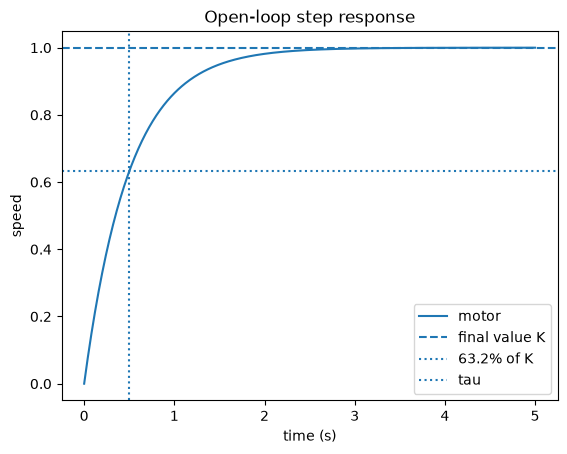

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct

K, tau = 1, 0.5                      # motor gain and time constant
G = ct.tf([K], [tau, 1])             # transfer function K / (tau*s + 1)

t = np.linspace(0, 5, 500)           # 500 time points from 0 to 5 s
t, y = ct.step_response(G, t)        # response to a step input

plt.plot(t, y, label="motor")
plt.axhline(K, ls="--", label="final value K")
plt.axhline(0.632 * K, ls=":", label="63.2% of K")
plt.axvline(tau, ls=":", label="tau")
plt.xlabel("time (s)"); plt.ylabel("speed")
plt.title("Open-loop step response"); plt.legend(); plt.show()

In [3]:
def make_pid(Kp, Ki=0.0, Kd=0.0):
    C = ct.tf([Kp], [1])
    if Ki != 0:
        C = C + ct.tf([Ki], [1, 0])     # integral term Ki/s
    if Kd != 0:
        C = C + ct.tf([Kd, 0], [1])     # derivative term Kd*s
    return C

In [4]:
%%writefile ../src/metrics.py
import numpy as np

def step_metrics(t, y, setpoint=1.0):
    t = np.asarray(t)
    y = np.asarray(y)
    y_final = y[-1]                                   # value the response settles to

    overshoot = max(0.0, (y.max() - y_final) / abs(y_final) * 100)

    i10 = np.argmax(y >= 0.1 * y_final)               # first index above 10%
    i90 = np.argmax(y >= 0.9 * y_final)               # first index above 90%
    rise_time = t[i90] - t[i10]

    outside = np.where(np.abs(y - y_final) > 0.02 * abs(y_final))[0]
    if len(outside) == 0:
        settling_time = 0.0
    elif outside[-1] == len(t) - 1:
        settling_time = np.nan                        # never settled in this window
    else:
        settling_time = t[outside[-1] + 1]            # last time outside the 2% band

    return {"overshoot": overshoot,
            "rise_time": rise_time,
            "settling_time": settling_time,
            "sse": setpoint - y_final}                # steady-state error

Writing ../src/metrics.py
